# CesiCDP · Capacitated Vehicle Routing Problem (CVRP)
## Deliverable 1 — rigorous mathematical modeling and visual validation

**Research story.** A depot must dispatch a limited fleet of identical-capacity trucks to satisfy customer demands. How can we represent *every admissible plan* mathematically and identify the plan with minimum total distance?

**Scope:** the **basic CVRP only** (Level B). We intentionally do **not** model delivery time windows, time-dependent congestion, travel-time penalties, multi-depots, heterogeneous vehicle capacity, split deliveries, or stochastic demand. Those are different modeling extensions.

**What this notebook does:**
1. Specifies a **parameterized** dataset and modeling assumptions.
2. Explains graph and cost representations with plots.
3. Defines decision variables, a linear objective, **all** core MILP constraints, and subtour elimination.
4. Gives a formal **NP-hardness proof**.
5. Explains why the constraints characterize feasible CVRP tours.
6. Provides a detailed, independent **feasibility checker** and validates manually supplied routes.
7. Reads a **real CVRPLIB benchmark**, `A-n32-k5`, and checks a *published reference solution* (not produced by our algorithm).
8. Explores constraints, scaling, and input sensitivity graphically.

> **What it deliberately does NOT do:** construct or optimize routes using a heuristic, metaheuristic, exact solver, or brute-force search. According to the assignment, **no solver implementation is required at the first modeling checkpoint**.

**Editing policy:** every real-world quantity — customer count $n$, depot, coordinates, travel costs $d_{ij}$, vehicle count $K$, shared capacity $Q$, and demands $q_i$ — is **input data**. The numerical examples only illustrate these general equations. None of their values are embedded in the mathematical model.

## Notebook navigation / deliverable checklist

- [x] Context and problem scope
- [x] Formal data, notation, and assumptions
- [x] Decision variables and domains
- [x] Objective function and full ILP/MILP formulation
- [x] All feasibility constraints, including subtour elimination
- [x] NP-hardness proof (TSP reduction)
- [x] Illustrative model and constraint visualization
- [x] Synthetic, parameterized data demonstrations
- [x] Real CVRPLIB instance and independent reference validation
- [x] Mathematical-model sizing and limitations
- [x] Bibliographic references
- [ ] Tutor review, feedback, and correction log (to be completed by the team)

**Storytelling principle:** each section asks a concrete question, introduces the matching model component, and visually demonstrates why it matters.

## 0 · Execution and reproducibility

**Recommended dependencies:** `numpy`, `pandas`, `matplotlib`, and `vrplib`.

```bash
pip install numpy pandas matplotlib vrplib
```

`vrplib` is the preferred parser for real benchmark files. Because notebooks are often opened offline, an explicitly limited **fallback parser** is included for a *single-depot EUC_2D CVRP file* such as the bundled `A-n32-k5` example. It does not support every VRPLIB edge-weight format. Install `vrplib` for general-purpose instance loading.

The reference instance and solution are embedded as text, allowing a notebook-only download to reproduce the example without network access. The code writes temporary copies to a local `cvrp_modeling_data/` directory only when needed; it does not download external resources.

**Outputs** are explanatory charts, input diagnostics, and feasibility results; **not optimized solutions**.

In [1]:
from __future__ import annotations

# Standard library dependencies: portable file paths, immutable configurations,
# annotations, regex parsing, and integer arithmetic.
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
import math
import re
import warnings

# Scientific Python libraries are used for data analysis and plotting ONLY.
# No optimization solver or metaheuristic package is imported.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display

try:
    import vrplib  # Preferred, official parser used in the later project phases.
    VRPLIB_AVAILABLE = True
except ImportError:
    vrplib = None
    VRPLIB_AVAILABLE = False

# Sensible display settings affect chart readability, never model constraints.
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 105,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 20)

print("vrplib installed:", VRPLIB_AVAILABLE)
print("NumPy:", np.__version__, "· Matplotlib:", plt.matplotlib.__version__)

vrplib installed: False
NumPy: 2.3.5 · Matplotlib: 3.10.8


## 1 · From a delivery network to a graph

Let $G=(V,A)$ be a directed graph, where:

- $V=\{0,1,\ldots,n\}$: depot $0$ and $n$ customers $C=V\setminus\{0\}$.
- $A=\{(i,j):i,j\in V,\;i\ne j\}$: feasible *inter-location* arcs (no self-loops). The complete-graph formulation assumes all pairs are reachable; an unreachable road connection should be removed or replaced by a correctly computed shortest-path cost.
- $F=\{1,\ldots,K\}$: the set of available **identical-capacity** trucks, at most $K$ used.
- $Q>0$: payload capacity for **every** truck.
- $q_i\ge 0$: demand of customer $i\in C$, with $q_0=0$.
- $d_{ij}\ge 0$: deterministic distance/cost from $i$ to $j$; $d_{ii}$ is unused.
- Optional $p_i=(a_i,b_i)$: coordinates for **visualization** or generation of a metric cost matrix. Coordinates are not required if a road-distance matrix is supplied.

**Assumptions:** one depot, each customer visited exactly once by one truck (*no split delivery*); a route starts and finishes at the same depot; no vehicle can exceed its capacity; unused vehicles are allowed; input data and costs are known; no time windows.

We optimize **distance**, rather than time, so results can be compared against standard distance-based CVRPLIB benchmarks. A fixed travel-time matrix could be substituted in a different *static-cost* CVRP without changing the algebra; varying travel time with departure time is outside scope.

### 1.1 · The difference between a parameter and a hard-coded decision

The *formula* $\sum_{i\in C}q_i y_{ik}\le Qz_k$ never changes. Only the supplied instance values $q_i$, $Q$, and $K$ change. A small demonstration with chosen numbers is not a restriction on the general model.

**Editable synthetic-data configuration:** the following values are illustrative defaults only. Change them to visualize different sizes, capacities, fleet limits, customer layouts, and demand distributions. There is **no optimizer** in the generator.

In [2]:
@dataclass(frozen=True)
class SyntheticConfig:
    # Every attribute below belongs to the input configuration, not to the ILP.
    n_customers: int = 42
    max_vehicles: int = 8
    vehicle_capacity: float = 35.0
    min_demand: int = 1
    max_demand: int = 9
    coordinate_max: float = 100.0
    depot_xy: tuple[float, float] = (50.0, 50.0)
    layout: str = "uniform"  # Other supported layout: "clustered".
    seed: int = 2026
    distance_policy: str = "raw"  # "raw", "nearest_integer", or "ceil".

# Change only this cell to change the synthetic *instance* across its plots.
SYNTHETIC = SyntheticConfig()

# A separately configurable small teaching example for route feasibility:
# these are illustrative example inputs, not limits imposed by the model.
EXAMPLE_COORDS = np.array([
    [50, 50], [14, 70], [21, 42], [35, 16],
    [75, 76], [86, 45], [62, 20],
], dtype=float)
EXAMPLE_DEMANDS = np.array([0, 6, 5, 4, 7, 3, 2], dtype=float)
EXAMPLE_CAPACITY = 16.0
EXAMPLE_MAX_VEHICLES = 3
EXAMPLE_ROUTES = [[1, 2, 3], [4, 5, 6]]  # Hand-written, NOT computed.

### 1.2 · A reusable, validated instance container

The instance container checks **data consistency**, not optimality. A minimal fleet lower bound is $\lceil (\sum_i q_i)/Q\rceil$; the inequality $\sum_i q_i\le KQ$ is necessary but not sufficient for packing customers into $K$ trucks. Example: three customers with demand 6 each, two trucks of capacity 10: total demand 18 is below 20, but the customers cannot fit in two unsplittable routes.

For convenience in code, every instance is internally **reindexed so the depot is location 0**. A mapping is retained for source dataset identifiers.

In [3]:
@dataclass
class CVRPInstance:
    name: str
    demands: np.ndarray          # One demand per node; depot demand must be 0.
    capacity: float               # Shared capacity of all K vehicles.
    max_vehicles: int             # Fleet upper bound; can differ by instance.
    distances: np.ndarray         # Matrix [node, node], supplied or generated.
    coordinates: np.ndarray | None = None
    original_ids: np.ndarray | None = None
    source: str = "synthetic"
    distance_policy: str = "raw"

    @property
    def n_customers(self) -> int:
        return len(self.demands) - 1

    @property
    def nodes(self) -> np.ndarray:
        return np.arange(len(self.demands))

    def check_input(self) -> list[str]:
        """Return problems, instead of silently assuming the data are valid."""
        problems = []
        m = len(self.demands)
        D = np.asarray(self.distances)
        if m < 2:
            problems.append("At least one customer is required for this demonstration.")
        if not isinstance(self.max_vehicles, (int, np.integer)) or self.max_vehicles < 1:
            problems.append("Fleet size must be a positive integer.")
        if not np.isfinite(self.capacity) or self.capacity <= 0:
            problems.append("Vehicle capacity must be strictly positive.")
        if len(np.asarray(self.demands).shape) != 1:
            problems.append("Demand vector must be one-dimensional.")
        elif not np.all(np.isfinite(self.demands)) or np.any(self.demands < 0):
            problems.append("Demands must be finite and nonnegative.")
        if len(self.demands) and not np.isclose(self.demands[0], 0):
            problems.append("The depot must have zero delivery demand.")
        if D.shape != (m, m):
            problems.append(f"Cost matrix has shape {D.shape}, expected {(m,m)}.")
        elif not np.all(np.isfinite(D)) or np.any(D < 0):
            problems.append("Distances must be finite and nonnegative.")
        if self.coordinates is not None and np.asarray(self.coordinates).shape != (m, 2):
            problems.append("Coordinates must have shape (number_of_nodes, 2).")
        if self.original_ids is not None and len(self.original_ids) != m:
            problems.append("Original ID mapping length does not match the instance.")
        if not problems and np.any(self.demands[1:] > self.capacity):
            problems.append("At least one customer demand exceeds one truck's capacity.")
        return problems


def euclidean_cost_matrix(coords: np.ndarray, policy: str = "raw") -> np.ndarray:
    """Compute pairwise 2-D straight-line distances; no routing takes place.

    'nearest_integer' intentionally uses floor(d + 0.5), rather than np.round:
    np.round uses ties-to-even, whereas many benchmark conventions use
    nearest-integer rounding. Always verify the convention per instance set.
    """
    coords = np.asarray(coords, dtype=float)
    delta = coords[:, None, :] - coords[None, :, :]
    D = np.sqrt(np.sum(delta * delta, axis=2))
    if policy == "raw":
        pass
    elif policy == "nearest_integer":
        D = np.floor(D + 0.5)
    elif policy == "ceil":
        D = np.ceil(D)
    else:
        raise ValueError("distance policy must be raw, nearest_integer, or ceil")
    np.fill_diagonal(D, 0.0)
    return D


def generate_synthetic(cfg: SyntheticConfig) -> CVRPInstance:
    """Generate input only. Never creates, evaluates, or optimizes routes."""
    if cfg.n_customers < 1 or cfg.min_demand < 0 or cfg.min_demand > cfg.max_demand:
        raise ValueError("Invalid customer count or demand range")
    rng = np.random.default_rng(cfg.seed)
    n = cfg.n_customers
    if cfg.layout == "uniform":
        customer_coords = rng.uniform(0, cfg.coordinate_max, size=(n, 2))
    elif cfg.layout == "clustered":
        centers = rng.uniform(0.15, 0.85, size=(3, 2)) * cfg.coordinate_max
        owners = rng.integers(0, len(centers), size=n)
        customer_coords = centers[owners] + rng.normal(
            0, 0.075 * cfg.coordinate_max, size=(n, 2)
        )
        customer_coords = np.clip(customer_coords, 0, cfg.coordinate_max)
    else:
        raise ValueError("Unknown layout. Use uniform or clustered.")
    coords = np.vstack([np.array(cfg.depot_xy), customer_coords])
    demands = np.r_[0, rng.integers(cfg.min_demand, cfg.max_demand + 1, n)]
    instance = CVRPInstance(
        name=f"Synthetic ({cfg.layout}, n={n}, seed={cfg.seed})",
        demands=demands.astype(float),
        capacity=float(cfg.vehicle_capacity),
        max_vehicles=int(cfg.max_vehicles),
        distances=euclidean_cost_matrix(coords, cfg.distance_policy),
        coordinates=coords,
        original_ids=np.arange(n + 1),
        source="generated data",
        distance_policy=cfg.distance_policy,
    )
    return instance

synthetic = generate_synthetic(SYNTHETIC)
small = CVRPInstance(
    name="Handwritten teaching example",
    demands=EXAMPLE_DEMANDS.copy(),
    capacity=EXAMPLE_CAPACITY,
    max_vehicles=EXAMPLE_MAX_VEHICLES,
    distances=euclidean_cost_matrix(EXAMPLE_COORDS),
    coordinates=EXAMPLE_COORDS,
    original_ids=np.arange(len(EXAMPLE_DEMANDS)),
)
for inst in (synthetic, small):
    errors = inst.check_input()
    print(f"{inst.name}: n={inst.n_customers}, K={inst.max_vehicles}, "
          f"Q={inst.capacity}, demand={inst.demands[1:].sum():.0f}, "
          f"input_errors={errors}")

Synthetic (uniform, n=42, seed=2026): n=42, K=8, Q=35.0, demand=228, input_errors=[]
Handwritten teaching example: n=6, K=3, Q=16.0, demand=27, input_errors=[]


### 1.3 · Visual question: where are the customers, and how large are their demands?

The marker sizes represent demand, **not route assignments**. The depot marker is separate. This plot demonstrates why geographic location and payload both matter; spatially close customers might collectively exceed a truck's capacity.

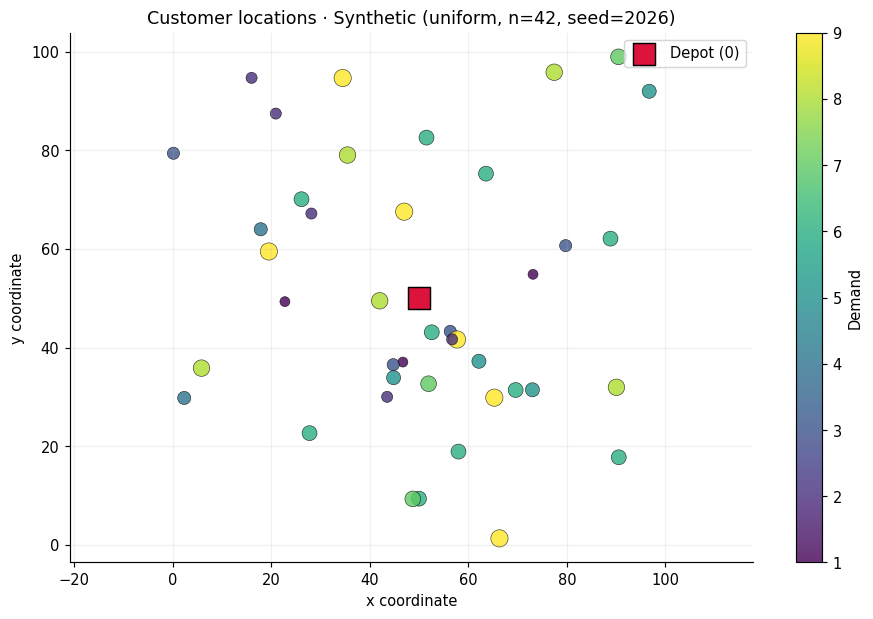

In [4]:
def plot_customer_map(instance: CVRPInstance, title: str | None = None, label: bool = False):
    """Show spatial inputs; optional coordinates are mandatory for this plot."""
    xy = instance.coordinates
    if xy is None:
        print("No coordinates provided; mapping skipped (distance matrix still usable).")
        return
    fig, ax = plt.subplots(figsize=(9, 6))
    q = instance.demands[1:]
    sizes = 35 + 15 * q / max(1, float(q.max())) * 7
    scatter = ax.scatter(xy[1:, 0], xy[1:, 1], s=sizes,
                         c=q, cmap="viridis", alpha=0.8, edgecolor="black", lw=0.4)
    ax.scatter([xy[0,0]], [xy[0,1]], marker="s", s=220, color="crimson",
               edgecolor="black", label="Depot (0)", zorder=5)
    if label and instance.n_customers <= 55:
        for i, (x, y) in enumerate(xy[1:], start=1):
            ax.annotate(str(i), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
    fig.colorbar(scatter, ax=ax, label="Demand")
    ax.set(xlabel="x coordinate", ylabel="y coordinate",
           title=title or f"Customer locations · {instance.name}")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()

plot_customer_map(synthetic)

### 1.4 · Demand profiles and elementary feasibility tests

Two easy necessary conditions for feasibility are:

$$\max_{i\in C}q_i\le Q,\qquad \sum_{i\in C}q_i\le KQ.$$

The capacity lower bound on **vehicles used** is:

$$L_K=\left\lceil\frac{\sum_{i\in C}q_i}{Q}\right\rceil.$$

**Caution:** these checks cannot prove full feasibility because unsplittable demands create a bin-packing restriction.

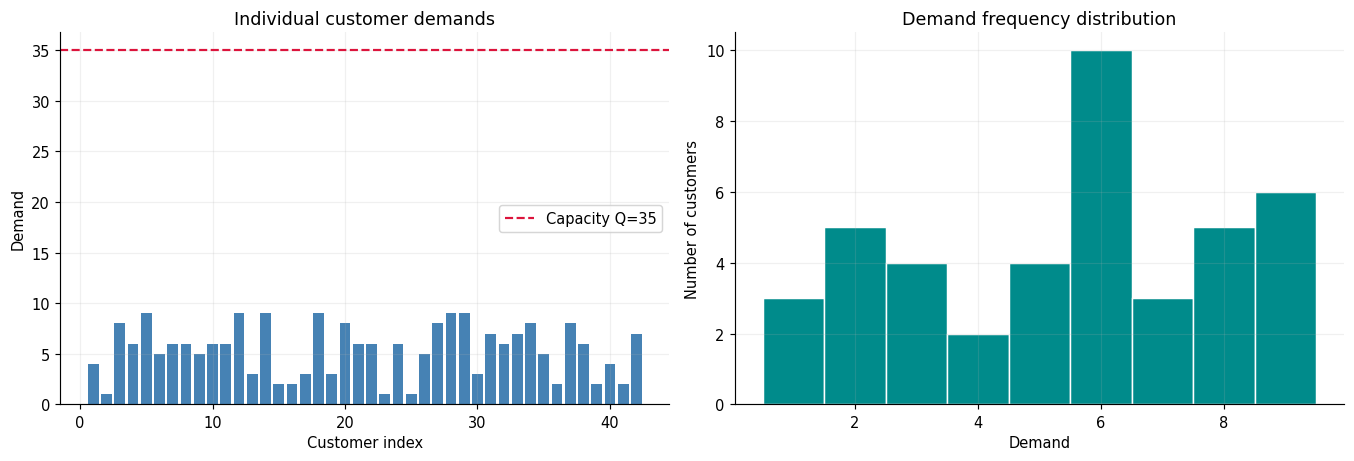

Total demand: 228 · available capacity KQ: 280
Necessary minimum trucks from aggregate capacity: 7
Individual demands within capacity: True
Aggregate demand within total fleet capacity: True


In [5]:
q = synthetic.demands[1:]
Q = synthetic.capacity
K = synthetic.max_vehicles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.bar(np.arange(1, len(q)+1), q, color="steelblue")
ax1.axhline(Q, color="crimson", linestyle="--", label=f"Capacity Q={Q:g}")
ax1.set(xlabel="Customer index", ylabel="Demand", title="Individual customer demands")
ax1.legend()
ax2.hist(q, bins=np.arange(q.min()-0.5, q.max()+1.5, 1), color="darkcyan",
         edgecolor="white")
ax2.set(xlabel="Demand", ylabel="Number of customers", title="Demand frequency distribution")
plt.tight_layout(); plt.show()

lower_bound = math.ceil(float(q.sum()) / Q)
print(f"Total demand: {q.sum():g} · available capacity KQ: {K*Q:g}")
print(f"Necessary minimum trucks from aggregate capacity: {lower_bound}")
print("Individual demands within capacity:", bool((q <= Q).all()))
print("Aggregate demand within total fleet capacity:", bool(q.sum() <= K*Q))

### 1.5 · Why capacities and distribution are separate issues

A vehicle can have spare capacity while all customers remain individually unassignable under the remaining fleet allocation. This is why aggregate capacity alone does not prove feasibility.

Below, **six-unit customers with ten-unit trucks** illustrate how the aggregate capacity bound can be satisfied and the actual packing still impossible. This is a conceptual counterexample, **not** a solution attempt.

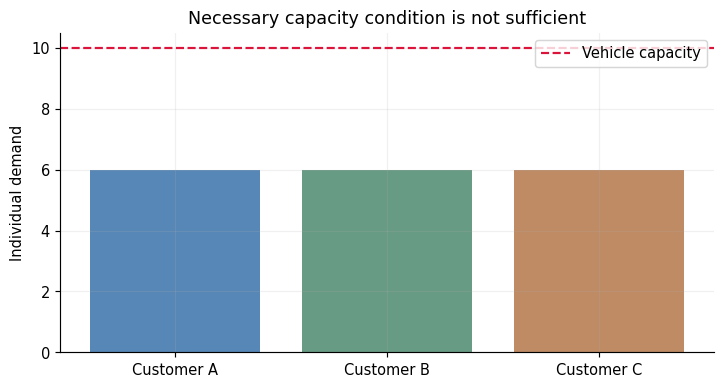

Sum of demand = 18 ≤ KQ = 20
But every pair has demand 12 > Q=10, so 3 vehicles would be required.


In [6]:
# These three figures are a logical counterexample, not a solver result.
packing_demands = np.array([6, 6, 6])
packing_Q, packing_K = 10, 2
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(["Customer A", "Customer B", "Customer C"], packing_demands,
       color=["#5787b7", "#689b84", "#be8b65"])
ax.axhline(packing_Q, color="crimson", linestyle="--", label="Vehicle capacity")
ax.set(ylabel="Individual demand", title="Necessary capacity condition is not sufficient")
ax.legend()
plt.tight_layout(); plt.show()
print("Sum of demand =", packing_demands.sum(), "≤ KQ =", packing_Q*packing_K)
print("But every pair has demand 12 > Q=10, so 3 vehicles would be required.")

## 2 · Decision variables: what exactly can be chosen?

For every truck $k\in F$ and arc $(i,j)\in A$:

$$x_{ijk}=\begin{cases}1,&\text{if truck }k\text{ travels directly from }i\text{ to }j,\\0,&\text{otherwise.}\end{cases}$$

For every customer $i\in C$ and truck $k\in F$:

$$y_{ik}=\begin{cases}1,&\text{if truck }k\text{ serves customer }i,\\0,&\text{otherwise.}\end{cases}$$

For each truck $k\in F$:

$$z_k=\begin{cases}1,&\text{if truck }k\text{ is used,}\\0,&\text{otherwise.}\end{cases}$$

For every customer $i\in C$ and truck $k\in F$, introduce an auxiliary **visit-order** variable $u_{ik}$.

$$u_{ik}=0\quad\text{if }y_{ik}=0;\qquad
1\le u_{ik}\le n\quad\text{if }y_{ik}=1.$$

The order variable is not an additional delivery decision: it exists to forbid customer-only cycles. It can be **continuous** because strict $+1$ sequencing constraints make it increase on every selected customer-to-customer arc; integer order variables are also allowed. With continuous $u$, the model is more precisely a **Mixed-Integer Linear Program (MILP)**, also commonly discussed under the broader PLNE/ILP heading.

**Why three kinds of binary variable?** $x$ expresses route *order*, $y$ identifies *assignment/load*, and $z$ distinguishes an *unused* truck from a real depot-to-depot route. These links will be enforced, not assumed.

### 2.1 · Visual interpretation of an arc decision

The diagram below illustrates one **hypothetical** truck route and the corresponding binary choices. It does **not** imply any optimization has happened.

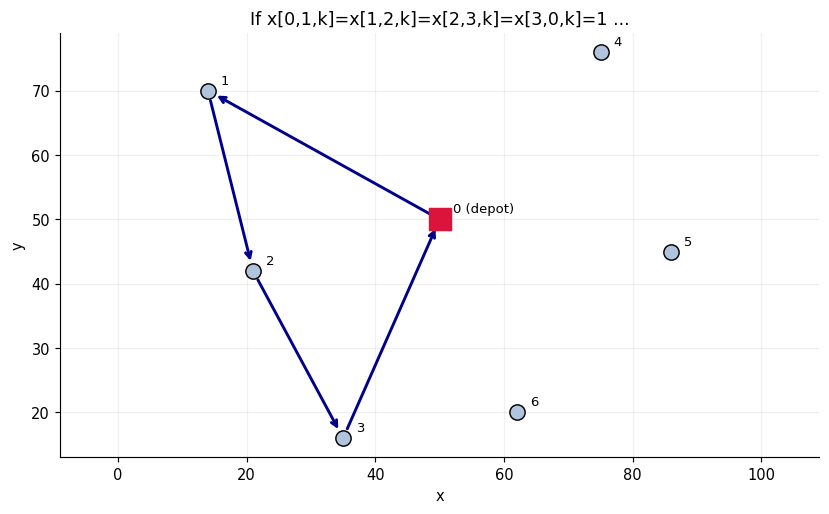

Active arcs in this illustrative route: [(0, 1), (1, 2), (2, 3), (3, 0)]


In [7]:
# Conceptual illustration drawn from the hand-written route [1,2,3].
path = [0, 1, 2, 3, 0]
xy = small.coordinates
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(xy[1:,0], xy[1:,1], s=110, color="lightsteelblue", edgecolor="black", zorder=3)
ax.scatter(xy[0,0], xy[0,1], s=230, marker="s", color="crimson", zorder=5)
for i,(x,y) in enumerate(xy):
    ax.text(x+2, y+1, f"{i}" + (" (depot)" if i==0 else ""), fontsize=9)
for a,b in zip(path[:-1], path[1:]):
    ax.annotate("", xy=xy[b], xytext=xy[a],
                arrowprops=dict(arrowstyle="->", color="darkblue", lw=2, shrinkA=7, shrinkB=7))
ax.set(xlabel="x", ylabel="y", title="If x[0,1,k]=x[1,2,k]=x[2,3,k]=x[3,0,k]=1 ...")
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout(); plt.show()
print("Active arcs in this illustrative route:", list(zip(path[:-1], path[1:])))

## 3 · Objective: minimize the **total distance traveled by all trucks**

$$\boxed{\min_{x,y,z,u}\; Z=\sum_{k\in F}\sum_{(i,j)\in A}d_{ij}x_{ijk}}$$

Each selected arc incurs its cost *once*. We include depot-to-customer, customer-to-customer, and customer-to-depot travel. The objective sums over all trucks; it does **not** minimize the longest route, the number of trucks, or delivery time.

Even if coordinates are available, the matrix $D=[d_{ij}]$ is the authoritative cost input. A road-based matrix may be asymmetric ($d_{ij}\neq d_{ji}$); the formulation still works. Standard symmetric Euclidean CVRPLIB examples are only a special case.

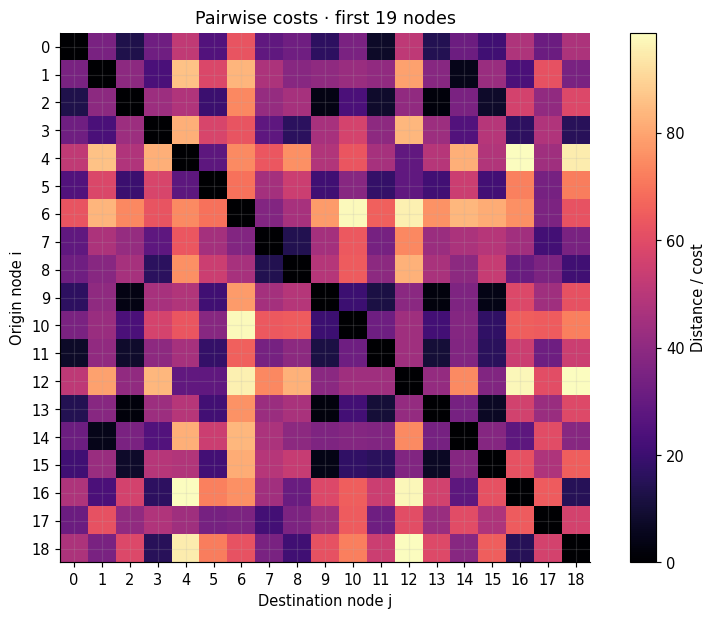

In [8]:
# Visualize the distance matrix. A small subset makes labels readable, while
# the full matrix remains available for mathematical evaluation and validation.
D = synthetic.distances
shown = min(D.shape[0], 19)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(D[:shown, :shown], cmap="magma", interpolation="nearest")
fig.colorbar(im, ax=ax, label="Distance / cost")
ax.set(xlabel="Destination node j", ylabel="Origin node i",
       title=f"Pairwise costs · first {shown} nodes")
ax.set_xticks(np.arange(shown)); ax.set_yticks(np.arange(shown))
plt.tight_layout(); plt.show()

## 4 · **Complete** CVRP integer-linear formulation

Let $C=\{1,\dots,n\}$, $V=C\cup\{0\}$, $F=\{1,\dots,K\}$, and $A=\{(i,j)\in V^2:i\neq j\}$.

The full formulation below uses **at most $K$ trucks**. If the assignment literally requires **exactly $K$ nonempty routes**, replace $z_k\in\{0,1\}$ by $z_k=1$ for all $k$ (and verify $K\le n$ and capacity feasibility). An at-most-$K$ fleet is the normal interpretation of available vehicles; *the chosen convention must be stated to the tutor*.

### (M0) Objective

$$\min\sum_{k\in F}\sum_{(i,j)\in A}d_{ij}x_{ijk}.$$

### (M1) Each customer is assigned exactly once

$$\boxed{\sum_{k\in F} y_{ik}=1\quad\forall i\in C.}$$

### (M2–M3) Each assigned truck enters and leaves its customers exactly once

$$\boxed{\sum_{j\in V\setminus\{i\}}x_{ijk}=y_{ik}
\quad\forall i\in C,\;\forall k\in F,}$$

$$\boxed{\sum_{j\in V\setminus\{i\}}x_{jik}=y_{ik}
\quad\forall i\in C,\;\forall k\in F.}$$

Together with (M1), these encode visit-once and conservation of flow.

### (M4–M5) Every used truck departs from and returns to the depot

$$\boxed{\sum_{j\in C}x_{0jk}=z_k\quad\forall k\in F,}$$

$$\boxed{\sum_{i\in C}x_{i0k}=z_k\quad\forall k\in F.}$$

A truck with $z_k=0$ has no assigned customers or selected arcs.

### (M6) Capacity of each truck

$$\boxed{\sum_{i\in C}q_i y_{ik}\le Q z_k\quad\forall k\in F.}$$

Since each customer has one assigned truck, no demand is split across trucks.

### (M7–M9) Order-based Miller–Tucker–Zemlin (MTZ) subtour elimination

$$\boxed{y_{ik}\le u_{ik}\le n y_{ik}
\quad\forall i\in C,\;\forall k\in F,}$$

$$\boxed{u_{jk}\ge u_{ik}+1-(n+1)(1-x_{ijk})
\quad\forall i,j\in C,\;i\ne j,\;\forall k\in F.}$$

When $x_{ijk}=1$, order must increase by at least 1. A cycle of customers would require $u_{i_1,k}<u_{i_2,k}<\cdots<u_{i_m,k}<u_{i_1,k}$, which is impossible. When $x_{ijk}=0$, the lower bound is redundant because $u_{ik}\le n$ and $u_{jk}\ge0$; the **valid big-$M$ coefficient is $n+1$**.

**Strength:** this order formulation still eliminates disconnected cycles if some demands $q_i=0$, unlike a naïve positive-demand load-based MTZ proof.

### (M10) Decision domains / forbidden self-loops

$$\boxed{x_{ijk}\in\{0,1\}\quad\forall (i,j)\in A,\ k\in F,}$$
$$\boxed{y_{ik}\in\{0,1\}\quad\forall i\in C,\ k\in F,}$$
$$\boxed{z_k\in\{0,1\}\quad\forall k\in F,}$$
$$\boxed{u_{ik}\in\mathbb R_{\ge0}\quad\forall i\in C,\ k\in F.}$$

There are **no** $x_{iik}$ variables (or equivalently, set them to 0). We assume all input distances are finite and all truck capacities identical.

### Optional (not required): symmetry reduction

$$z_k\ge z_{k+1}\quad (k=1,\dots,K-1).$$

Trucks are interchangeable, so unused trucks can be placed after active trucks. This changes *which truck label* is used, not the objective or set of physical routes. It is an optional improvement to a future ILP implementation, not a needed CVRP rule.

### 4.1 · Constraint-to-business-rule traceability

| Mathematical rule | Operational meaning | Failure if omitted |
|---|---|---|
| M1: $\sum_k y_{ik}=1$ | Every customer served once | Skipped or multiply assigned customers |
| M2–M3: incoming/outgoing $=y_{ik}$ | Continuity and visit-once per truck | Fragmented or unmatched travel arcs |
| M4–M5: depot degree $=z_k$ | Active route begins and ends at depot | Open routes / unused truck inconsistencies |
| M6: $\sum_i q_i y_{ik}\le Qz_k$ | Payload capacity | Overloaded trucks |
| M7–M9: $u$ bounds and increasing order | No customer-only cycles | Disconnected subtours |
| M10: binary domains and $i\ne j$ | Yes/no travel decisions and no self-loops | Fractional or meaningless trips |

**Why we do not add** a fixed route length, service time, or time-window constraint: those are not part of the basic CVRP selected for this checkpoint.

### 4.2 · Visual proof: why flow constraints alone do not eliminate subtours

Imagine one truck with a valid depot loop $0\to1\to2\to0$ and a disconnected customer loop $3\to4\to3$. Every customer still has one incoming and one outgoing arc, but the second loop is unreachable from the depot. It is **not** a valid delivery plan.

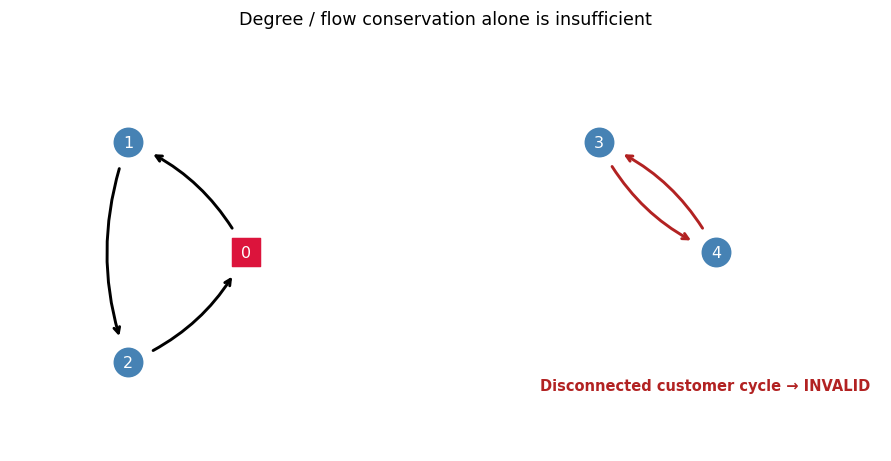

In [9]:
# Purely schematic node positions; edges deliberately exhibit a bad subtour.
positions = {0:(0,0), 1:(-1,1), 2:(-1,-1), 3:(3,1), 4:(4,0)}
bad_arcs = [(0,1),(1,2),(2,0),(3,4),(4,3)]
fig, ax = plt.subplots(figsize=(9, 4.5))
for v,(x,y) in positions.items():
    ax.scatter([x],[y],s=380,marker="s" if v==0 else "o",
               color="crimson" if v==0 else "steelblue",zorder=5)
    ax.text(x,y,str(v),color="white",ha="center",va="center",fontsize=11,zorder=6)
for a,b in bad_arcs:
    ax.annotate("", xy=positions[b], xytext=positions[a],
                arrowprops=dict(arrowstyle="->", lw=2,
                                color="firebrick" if a>=3 else "black",
                                connectionstyle="arc3,rad=0.19", shrinkA=19, shrinkB=19))
ax.text(2.5,-1.25,"Disconnected customer cycle → INVALID",color="firebrick",weight="bold")
ax.set(title="Degree / flow conservation alone is insufficient", xlim=(-2,5.4),ylim=(-1.8,2))
ax.axis("off")
plt.tight_layout(); plt.show()

### 4.3 · Why MTZ eliminates the disconnected cycle

If the bad tour uses arcs $3\to4$ and $4\to3$ for truck $k$, the order equations imply

$$u_{4k}\ge u_{3k}+1\quad\text{and}\quad
u_{3k}\ge u_{4k}+1.$$

Adding gives $0\ge2$, a contradiction. This argument applies to any customer-only cycle, even with zero-demand customers.

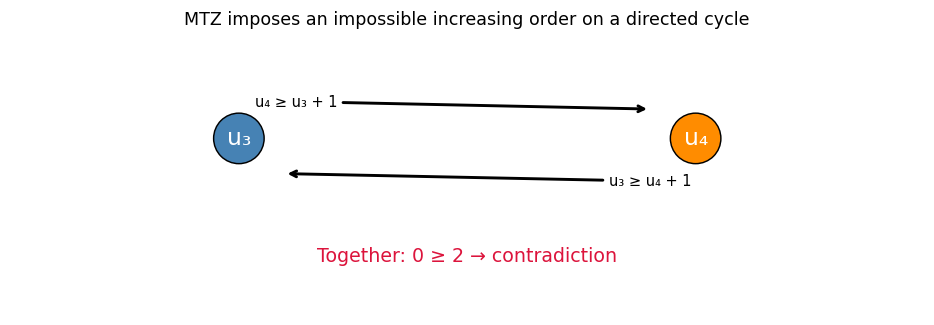

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.scatter([1,3], [1,1], s=1200, c=["steelblue","darkorange"], edgecolor="black")
ax.text(1,1,"u₃",color="white",ha="center",va="center",fontsize=16)
ax.text(3,1,"u₄",color="white",ha="center",va="center",fontsize=16)
ax.annotate("u₄ ≥ u₃ + 1",(2.8,1.25),(1.25,1.25),
            arrowprops={"arrowstyle":"->","lw":2},ha="center",va="bottom")
ax.annotate("u₃ ≥ u₄ + 1",(1.2,.70),(2.8,.70),
            arrowprops={"arrowstyle":"->","lw":2},ha="center",va="top")
ax.text(2,-.05,"Together: 0 ≥ 2 → contradiction",ha="center",color="crimson",fontsize=13)
ax.set(xlim=(0,4),ylim=(-.5,1.9),title="MTZ imposes an impossible increasing order on a directed cycle")
ax.axis("off")
plt.tight_layout(); plt.show()

### 4.4 · Why this formulation is sufficient and necessary

**(Necessary)** Take any physically feasible CVRP solution. Assign $z_k=1$ exactly for used trucks; set $y_{ik}=1$ exactly on the truck that serves customer $i$; set $x_{ijk}=1$ on consecutive route arcs, including the depot legs; set $u_{ik}$ to the position (1,2,...) of $i$ on truck $k$, or 0 when unassigned. All the equations hold.

**(Sufficient)** M1 assigns every customer to exactly one truck; M2/M3 force exactly one incoming and outgoing arc for the assigned customer; M4/M5 give each used truck exactly one depot departure and return; M7–M9 forbid every customer-only subtour. Hence the selected arcs for each used truck form exactly one connected directed route from and back to the depot. M6 enforces capacity. Therefore every feasible model assignment corresponds to a legal CVRP plan.

**Important limitation:** these statements assume all valid required arcs can be represented in $A$ and each distance is well-defined. In this notebook the full directed graph is used. The model does not imply symmetry or a triangle inequality unless the data supply them.

## 5 · Complexity proof: CVRP is NP-hard

### Decision version

**CVRP-DECISION** asks: given $G$, depot, $K$, $Q$, demands $q_i$, distances $d_{ij}$ and a budget $B$, is there a set of feasible routes with total cost $\le B$?

### Polynomial-time reduction from TSP-DECISION

1. Start from a TSP-DECISION instance with vertices $\{0,1,\dots,n\}$, nonnegative distances $d_{ij}$ and target budget $B$.
2. Build the CVRP instance on the **same** graph and costs. Choose node 0 as the depot, set **$K=1$**, let $q_i=1$ for all $i>0$, and choose **$Q=n$**. This construction is polynomial-time.
3. The single vehicle has enough capacity for all customers: $\sum_{i>0}q_i=n\le Q$.
4. With one truck and every customer visited exactly once, a feasible CVRP tour is exactly a TSP Hamiltonian tour starting and ending at depot 0.
5. The same tour has the same cost. Thus TSP has a tour of cost at most $B$ **if and only if** the constructed CVRP instance does.

Because TSP-DECISION is NP-complete, CVRP-DECISION is **NP-hard**. A certificate is a list of $\le K$ customer sequences; its coverage, capacity, depot and total-cost conditions can be verified in polynomial time, so **CVRP-DECISION is NP-complete** under the standard finite/rational input encoding. Consequently CVRP **optimization is NP-hard**.

**What this means for the project:** a compact MILP mathematically defines exact feasibility and cost, but we should not assume an exact solver can scale to several thousand customers. An efficient heuristic/metaheuristic is a distinct *later* deliverable, not part of this modeling checkpoint.

## 6 · Independent feasibility validator (not an optimization algorithm)

A **route list** is a set of customer sequences. Example: `[[1, 2], [3, 4]]` represents $0\to1\to2\to0$ and $0\to3\to4\to0$. The depot is inserted by the checker and therefore must **not** appear within any customer sequence.

The following functions do **not search for routes**. They only assess routes provided by a human or benchmark source, identifying customer coverage, duplicated visits, capacity, depot, fleet and distance issues.

In [11]:
@dataclass
class ValidationResult:
    feasible: bool
    problems: list[str]
    route_loads: list[float]
    route_distances: list[float]
    total_distance: float
    customers_seen: int


def validate_routes(instance: CVRPInstance, routes: list[list[int]]) -> ValidationResult:
    """Validate an EXISTING route list; it never modifies or optimizes it.

    Every route is a customer-only sequence. It must contain valid integer IDs
    from 1...n; the depot (0) is implicit. Empty routes are ignored, so an
    available but unused truck is permitted. A vehicle is assigned at most one
    nonempty sequence, matching the fleet model.
    """
    issues = instance.check_input()
    loads, route_distances, visited = [], [], []
    active_routes = [r for r in routes if len(r) > 0]
    if len(active_routes) > instance.max_vehicles:
        issues.append(f"Fleet limit: used {len(active_routes)} > K={instance.max_vehicles}.")
    for vehicle_idx, route in enumerate(active_routes, start=1):
        invalid = [node for node in route if type(node) not in (int, np.int32, np.int64)
                   or not (1 <= int(node) <= instance.n_customers)]
        if invalid:
            issues.append(f"Route {vehicle_idx}: invalid customer/depot IDs: {invalid}.")
            loads.append(float("nan")); route_distances.append(float("nan"))
            continue
        visited.extend(route)
        load = float(np.sum(instance.demands[route]))
        loads.append(load)
        if load > instance.capacity + 1e-9:
            issues.append(f"Route {vehicle_idx}: load {load:g} exceeds Q={instance.capacity:g}.")
        path = [0] + list(route) + [0]
        route_distance = sum(float(instance.distances[a, b])
                             for a, b in zip(path[:-1], path[1:]))
        route_distances.append(route_distance)
    counts = Counter(visited)
    duplicate = sorted(i for i, number in counts.items() if number > 1)
    missing = sorted(set(range(1, instance.n_customers + 1)) - set(visited))
    if duplicate:
        issues.append(f"Duplicate customer(s): {duplicate}.")
    if missing:
        issues.append(f"Missing customer(s): {missing}.")
    total = float(sum(route_distances))
    return ValidationResult(
        feasible=not issues, problems=issues, route_loads=loads,
        route_distances=route_distances, total_distance=total,
        customers_seen=len(visited),
    )


def summarize_route_check(instance: CVRPInstance, routes: list[list[int]]) -> pd.DataFrame:
    result = validate_routes(instance, routes)
    print("Feasible:", result.feasible)
    print("Distance:", round(result.total_distance, 3))
    print("Issues:", result.problems if result.problems else "none")
    table = pd.DataFrame({
        "Truck": range(1, len(result.route_loads) + 1),
        "Load": result.route_loads,
        "Capacity": instance.capacity,
        "Distance": result.route_distances,
    })
    display(table)
    return table

small_check_table = summarize_route_check(small, EXAMPLE_ROUTES)
assert validate_routes(small, EXAMPLE_ROUTES).feasible

Feasible: True
Distance: 272.665
Issues: none


,Truck,Load,Capacity,Distance
0,1,15.0,16.0,136.735714
1,2,12.0,16.0,135.929582


### 6.1 · Plot two explicitly supplied hand-written routes

The plotted routes are **not the solution of an optimizer**. They demonstrate exactly how the mathematical model interprets a valid route list and its distance cost.

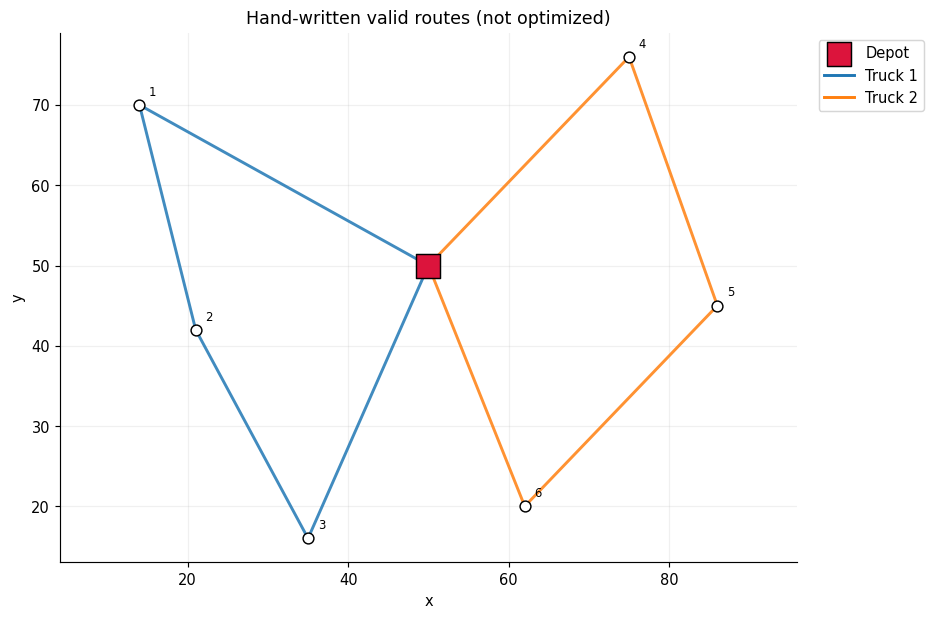

In [12]:
def plot_routes(instance: CVRPInstance, routes: list[list[int]], title: str):
    """Draw only user-supplied or reference routes. No route construction."""
    if instance.coordinates is None:
        print("Skipping route drawing: this instance does not include coordinates.")
        return
    fig, ax = plt.subplots(figsize=(9, 6))
    xy = instance.coordinates
    colors = plt.get_cmap("tab10")
    ax.scatter(xy[1:,0], xy[1:,1], s=55, color="white",
               edgecolor="black", zorder=5)
    ax.scatter(xy[0,0], xy[0,1], s=250, marker="s",
               color="crimson", edgecolor="black", zorder=6, label="Depot")
    for i,(x,y) in enumerate(xy[1:],start=1):
        if instance.n_customers <= 45:
            ax.text(x+1.2, y+1.2, str(i), fontsize=8)
    for k, route in enumerate(routes):
        if not route:
            continue
        path = [0] + list(route) + [0]
        color = colors(k % 10)
        for a,b in zip(path[:-1],path[1:]):
            ax.plot(xy[[a,b],0],xy[[a,b],1], color=color,alpha=.85,lw=2)
        ax.plot([],[],color=color,lw=2,label=f"Truck {k+1}")
    ax.set(xlabel="x",ylabel="y",title=title)
    ax.set_aspect("equal",adjustable="datalim")
    ax.legend(loc="upper left",bbox_to_anchor=(1.02,1))
    plt.tight_layout(); plt.show()

plot_routes(small, EXAMPLE_ROUTES, "Hand-written valid routes (not optimized)")

### 6.2 · Load profiles and capacity slack

Because the rules constrain **per-route demand**, not aggregate demand alone, it is useful to visualize individual vehicle loads and unused capacity. All loads below are calculated from the hand-written route list.

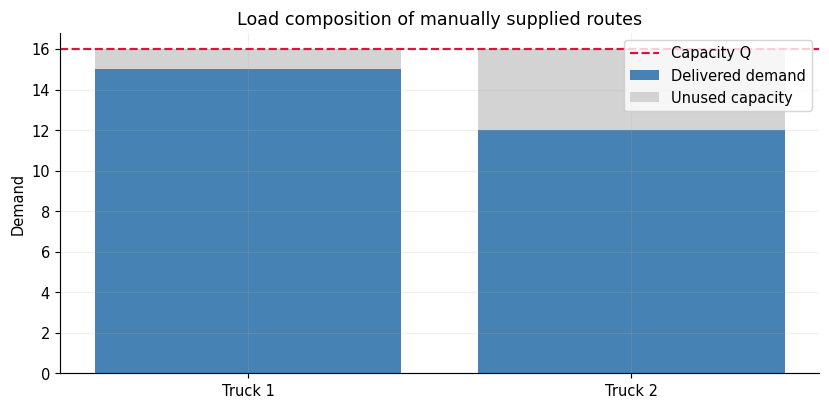

In [13]:
result_small = validate_routes(small, EXAMPLE_ROUTES)
loads = np.array(result_small.route_loads)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(loads))
ax.bar(x, loads, label="Delivered demand", color="steelblue")
ax.bar(x, small.capacity - loads, bottom=loads, label="Unused capacity", color="lightgray")
ax.axhline(small.capacity, color="crimson", linestyle="--", label="Capacity Q")
ax.set_xticks(x, [f"Truck {i+1}" for i in x])
ax.set(ylabel="Demand", title="Load composition of manually supplied routes")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### 6.3 · Test **invalid** user-supplied routes

These tests are deliberate counterexamples: omitted customers, a duplicate delivery, fleet overuse, and a load exceeding $Q$. They verify that the checker rejects each violation and explain the business consequence.

,Scenario,Feasible,Errors,Reason
0,valid manual routes,True,0,—
1,one customer missing,False,1,Missing customer(s): [6].
2,duplicate customer,False,2,Route 2: load 18 exceeds Q=16.; Duplicate cust...
3,over-capacity route,False,1,Route 1: load 22 exceeds Q=16.
4,depot used as customer,False,2,Route 1: invalid customer/depot IDs: [0].; Mis...
5,too many trucks,False,1,Fleet limit: used 4 > K=3.


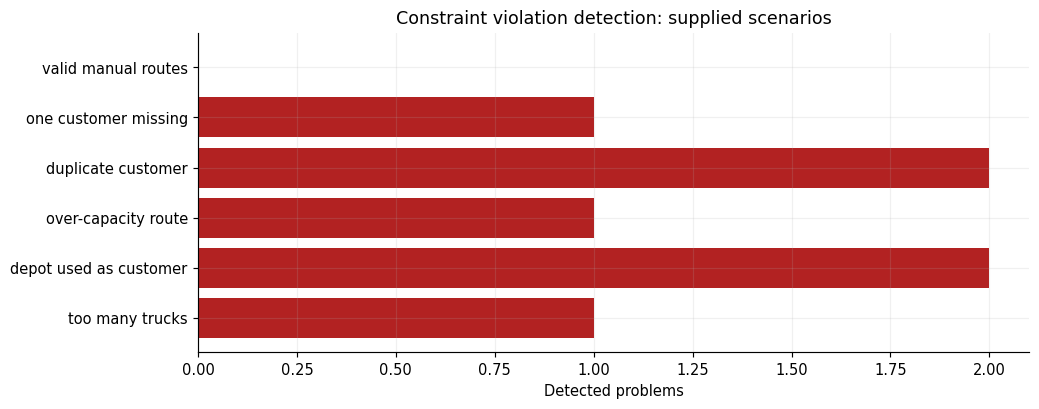

In [14]:
# Each case is explicitly constructed to violate a particular rule.
# Notice: test cases change the INPUT ROUTES, not the solver (there is none).
cases = {
    "valid manual routes": [[1,2,3], [4,5,6]],
    "one customer missing": [[1,2,3], [4,5]],
    "duplicate customer": [[1,2,3], [4,5,6,1]],
    "over-capacity route": [[1,2,3,4], [5,6]],
    "depot used as customer": [[0,1,2,3], [4,5,6]],
    "too many trucks": [[1],[2],[3],[4,5,6]],
}
case_rows = []
for name, routes in cases.items():
    result = validate_routes(small, routes)
    case_rows.append({"Scenario":name,"Feasible":result.feasible,
                      "Errors":len(result.problems),
                      "Reason":"; ".join(result.problems) if result.problems else "—"})
scenario_table = pd.DataFrame(case_rows)
display(scenario_table)
assert scenario_table["Feasible"].tolist() == [True,False,False,False,False,False]

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(scenario_table["Scenario"], scenario_table["Errors"],
        color=["forestgreen" if good else "firebrick" for good in scenario_table["Feasible"]])
ax.set(xlabel="Detected problems", title="Constraint violation detection: supplied scenarios")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

### 6.4 · Reconstruct model variables from supplied routes, then verify the equations

A stronger check does not merely examine routes. It builds explicit $x$, $y$, $z$, and $u$ arrays from a **given** route list, and directly evaluates the ILP equations, including every MTZ inequality. This is useful for catching errors in the proposed mathematical notation **without running an optimizer**.

In [15]:
def certify_model_equations(instance: CVRPInstance, routes: list[list[int]]) -> dict:
    """Check every mathematical condition on a PROVIDED valid-route candidate.

    This is an exhaustive evaluator for equations M1-M10 on the input
    assignment; it is NOT a general ILP solver (no search, no branching,
    no route optimization). O(K*n^2) time is acceptable for small examples.
    """
    n, K = instance.n_customers, instance.max_vehicles
    V = n + 1
    if len([r for r in routes if r]) > K:
        raise ValueError("Cannot encode more routes than available trucks")
    x = np.zeros((K, V, V), dtype=int)
    y = np.zeros((K, V), dtype=int)
    z = np.zeros(K, dtype=int)
    u = np.zeros((K, V), dtype=float)
    active = [r for r in routes if r]
    for k, route in enumerate(active):
        z[k] = 1
        for position, customer in enumerate(route, start=1):
            if customer < 1 or customer > n:
                raise ValueError("Invalid customer ID")
            y[k, customer] = 1
            u[k, customer] = float(position)
        full_path = [0] + route + [0]
        for i, j in zip(full_path[:-1], full_path[1:]):
            x[k, i, j] = 1

    check = {}
    check["M1: each customer once"] = bool(np.all(y[:,1:].sum(axis=0) == 1))
    check["M2: outbound = assignment"] = bool(np.all(x[:,:, :].sum(axis=2)[:,1:] == y[:,1:]))
    check["M3: inbound = assignment"] = bool(np.all(x.sum(axis=1)[:,1:] == y[:,1:]))
    check["M4: leave depot"] = bool(np.all(x[:,0,1:].sum(axis=1) == z))
    check["M5: return to depot"] = bool(np.all(x[:,1:,0].sum(axis=1) == z))
    check["M6: capacities"] = bool(np.all(y[:,1:] @ instance.demands[1:] <= instance.capacity*z + 1e-9))
    check["M7: u lower bound"] = bool(np.all(y[:,1:] <= u[:,1:] + 1e-9))
    check["M8: u upper bound"] = bool(np.all(u[:,1:] <= n*y[:,1:] + 1e-9))
    mtz_ok = True
    for k in range(K):
        for i in range(1,V):
            for j in range(1,V):
                if i != j:
                    lhs = u[k,j]
                    rhs = u[k,i] + 1 - (n+1)*(1-x[k,i,j])
                    if lhs < rhs - 1e-9:
                        mtz_ok = False
                        break
    check["M9: subtour (MTZ)"] = mtz_ok
    check["M10: no self-loop"] = bool(np.all(np.diagonal(x,axis1=1,axis2=2)==0))
    cost = float(np.sum(x * instance.distances[None,:,:]))
    route_cost = validate_routes(instance, routes).total_distance
    check["Objective equals route cost"] = bool(np.isclose(cost,route_cost))
    return {"checks":check, "all_hold":all(check.values()), "cost":cost,
            "x":x,"y":y,"z":z,"u":u}

certificate = certify_model_equations(small, EXAMPLE_ROUTES)
display(pd.DataFrame({"Equation": list(certificate["checks"]),
                      "Holds": list(certificate["checks"].values())}))
assert certificate["all_hold"]
print("Verified ILP objective:", round(certificate["cost"],3))

,Equation,Holds
0,M1: each customer once,True
1,M2: outbound = assignment,True
2,M3: inbound = assignment,True
3,M4: leave depot,True
4,M5: return to depot,True
5,M6: capacities,True
6,M7: u lower bound,True
7,M8: u upper bound,True
8,M9: subtour (MTZ),True
9,M10: no self-loop,True


Verified ILP objective: 272.665


### 6.5 · What happens when demand is zero?

Zero-demand customers are legal inputs in the mathematical model. Subtour elimination **must still work**. Our visit-order-based MTZ uses $+1$ rather than $+q_i$ and is therefore not dependent on positive demands.

In [16]:
# Small zero-demand edge case: each customer still requires a visit.
zero_case = CVRPInstance(
    name="Zero-demand edge case",
    demands=np.array([0., 0., 0., 3.]), capacity=3., max_vehicles=2,
    distances=euclidean_cost_matrix(np.array([[0.,0.],[1.,0.],[2.,1.],[2.,2.]])),
    coordinates=np.array([[0.,0.],[1.,0.],[2.,1.],[2.,2.]]),
)
zero_routes = [[1,2,3]]   # Illustrative handwritten candidate.
print("Zero-demand case feasible:", validate_routes(zero_case,zero_routes).feasible)
print("MTZ and all model equations hold:", certify_model_equations(zero_case,zero_routes)["all_hold"])
assert certify_model_equations(zero_case,zero_routes)["all_hold"]

Zero-demand case feasible: True
MTZ and all model equations hold: True


## 7 · Read a **real** CVRPLIB benchmark instance

We now leave synthetic data and load **A-n32-k5** (Augerat et al., Set A): 31 customers, 5 trucks, shared capacity 100. Its cataloged optimal **integer-rounded distance** is 784, according to [CVRPLIB](https://galgos.inf.puc-rio.br/cvrplib/).

**Important benchmarking trap:** `vrplib.read_instance` computes *unrounded Euclidean* distances for `EUC_2D`. Several classic published reference costs, including Set A, assume **nearest-integer rounded Euclidean** distances instead. We make the choice explicit and validate the reference cost; we do not assume all benchmark families use the same convention.

**Fleet limit trap:** many `.vrp` files omit a `VEHICLES` field. For the `A-n32-k5` example, the Set A filename's `k5` is its published fleet count; the loader interprets it only when it follows this naming convention. For other data, supply a fleet bound explicitly. We never silently hard-code one fleet size for all instances.

In [17]:
# Embedded real Augerat A-n32-k5 benchmark instance for offline reproducibility.
# Source: https://github.com/mkalinowski/CVRP/blob/master/dane/A-n32-k5.vrp
# Canonical benchmark listing: https://galgos.inf.puc-rio.br/cvrplib/
# A user can replace this example with any supported .vrp file on disk.
EMBEDDED_VRP = 'NAME : A-n32-k5\nCOMMENT : (Augerat et al, Min no of trucks: 5, Optimal value: 784)\nTYPE : CVRP\nDIMENSION : 32\nEDGE_WEIGHT_TYPE : EUC_2D\nCAPACITY : 100\nNODE_COORD_SECTION\n1 82 76\n2 96 44\n3 50 5\n4 49 8\n5 13 7\n6 29 89\n7 58 30\n8 84 39\n9 14 24\n10 2 39\n11 3 82\n12 5 10\n13 98 52\n14 84 25\n15 61 59\n16 1 65\n17 88 51\n18 91 2\n19 19 32\n20 93 3\n21 50 93\n22 98 14\n23 5 42\n24 42 9\n25 61 62\n26 9 97\n27 80 55\n28 57 69\n29 23 15\n30 20 70\n31 85 60\n32 98 5\nDEMAND_SECTION\n1 0\n2 19\n3 21\n4 6\n5 19\n6 7\n7 12\n8 16\n9 6\n10 16\n11 8\n12 14\n13 21\n14 16\n15 3\n16 22\n17 18\n18 19\n19 1\n20 24\n21 8\n22 12\n23 4\n24 8\n25 24\n26 24\n27 2\n28 20\n29 15\n30 2\n31 14\n32 9\nDEPOT_SECTION\n1\n-1\n'

# These are REFERENCE routes from a published benchmark example, not routes
# discovered by our notebook. Customer IDs use the 0-based/Depot-0 convention.
# Source: https://ltu.diva-portal.org/smash/get/diva2%3A1972726/FULLTEXT01.pdf
EMBEDDED_SOL = 'Route #1: 21 31 19 17 13 7 26\nRoute #2: 12 1 16 30\nRoute #3: 27 24\nRoute #4: 29 18 8 9 22 15 10 25 5 20\nRoute #5: 14 28 11 4 23 3 2 6\nCost: 784\n'

DATA_DIR = Path.cwd() / "cvrp_modeling_data"
DATA_DIR.mkdir(exist_ok=True)
SAMPLE_VRP = DATA_DIR / "A-n32-k5.vrp"
SAMPLE_SOL = DATA_DIR / "A-n32-k5.sol"
if not SAMPLE_VRP.exists():
    SAMPLE_VRP.write_text(EMBEDDED_VRP, encoding="utf-8")
if not SAMPLE_SOL.exists():
    SAMPLE_SOL.write_text(EMBEDDED_SOL, encoding="utf-8")
print("Offline example data:", SAMPLE_VRP)

Offline example data: /mnt/data/cvrp_modeling_data/A-n32-k5.vrp


### 7.1 · A narrow **offline fallback** for `EUC_2D` benchmark data

The notebook prefers the actual `vrplib` package. If it is unavailable, a tiny reader of indexed coordinates, demands, and a single depot supports the embedded `A-n32-k5` sample. This fallback explicitly rejects other distance types rather than silently calculating incorrect costs.

For large or more complex benchmark formats, install `vrplib` and use its full reader.

In [18]:
def fallback_parse_simple_euc_2d(path: Path) -> dict:
    """Only the EUC_2D, one-depot subset needed for our offline demo.

    The official vrplib parser is preferred. This fallback is intentionally
    limited and fails loudly for unsupported edge-weight representations.
    """
    header, coords, demands, depot = {}, {}, {}, []
    section = None
    for raw_line in path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.upper() == "EOF":
            continue
        if line in {"NODE_COORD_SECTION", "DEMAND_SECTION", "DEPOT_SECTION"}:
            section = line
            continue
        if section == "NODE_COORD_SECTION":
            parts = line.split(); coords[int(parts[0])] = (float(parts[1]),float(parts[2]))
        elif section == "DEMAND_SECTION":
            parts = line.split(); demands[int(parts[0])] = float(parts[1])
        elif section == "DEPOT_SECTION":
            node = int(line)
            if node != -1:
                depot.append(node)
        else:
            if ":" in line:
                key,value=line.split(":",1)
                header[key.strip().lower()]=value.strip()
    if header.get("edge_weight_type","").upper() != "EUC_2D":
        raise NotImplementedError("Offline reader supports only EUC_2D. Install vrplib.")
    m = int(header["dimension"])
    if len(depot) != 1 or len(coords) != m or len(demands) != m:
        raise ValueError("Malformed sample or unsupported depot/coordinate sections")
    ids = sorted(coords)
    xy = np.array([coords[i] for i in ids])
    q = np.array([demands[i] for i in ids])
    # Mirror the key names returned by vrplib.read_instance.
    return {"name":header["name"],"type":header.get("type","CVRP"),
            "capacity":float(header["capacity"]),"dimension":m,
            "depot":np.array([ids.index(depot[0])]),"demand":q,
            "node_coord":xy,"edge_weight":euclidean_cost_matrix(xy),
            "edge_weight_type":"EUC_2D"}


def fleet_from_instance_metadata(data: dict, override: int | None = None) -> int:
    """Never assume an arbitrary fleet size when source data omit it."""
    if override is not None:
        return int(override)
    if "vehicles" in data:
        return int(data["vehicles"])
    name = str(data.get("name", ""))
    match = re.search(r"-k(\d+)$", name, flags=re.IGNORECASE)
    if match:
        return int(match.group(1))  # Documented Augerat-style naming convention.
    raise ValueError("Fleet size unavailable: provide fleet_override explicitly.")


def load_cvrp(path: str | Path, *, fleet_override: int | None = None,
              rounding: str = "nearest_integer") -> CVRPInstance:
    """Convert a VRPLIB instance to the parameterized mathematical data model.

    - vrplib is used when installed.
    - The fallback supports only EUC_2D, for an offline demonstration.
    - Preserves source node IDs and internally moves the depot to index 0.
    - Never silently discards an unsupported or absent cost matrix.
    """
    path = Path(path)
    data = vrplib.read_instance(str(path)) if VRPLIB_AVAILABLE else fallback_parse_simple_euc_2d(path)
    if str(data.get("type", "CVRP")).upper() != "CVRP":
        raise ValueError("This notebook models CVRP only.")
    depot_indices = np.atleast_1d(data.get("depot",[0])).astype(int)
    if len(depot_indices) != 1:
        raise ValueError("One depot is required for this basic CVRP model.")
    depot_idx = int(depot_indices[0])
    demand = np.asarray(data["demand"],dtype=float)
    source_D = np.asarray(data["edge_weight"],dtype=float)
    coords = (np.asarray(data["node_coord"],dtype=float)
              if "node_coord" in data else None)
    # Official vrplib EUC_2D weights may be unrounded. Applying the explicit
    # requested policy aligns Set A comparisons; do NOT assume all sets use it.
    if rounding == "nearest_integer":
        distance = np.floor(source_D + .5)
    elif rounding == "raw":
        distance = source_D.copy()
    elif rounding == "ceil":
        distance = np.ceil(source_D)
    else:
        raise ValueError("Unknown rounding policy")
    ids = np.arange(len(demand))
    perm = np.r_[depot_idx, ids[ids != depot_idx]]
    instance = CVRPInstance(
        name=str(data.get("name",path.stem)),
        demands=demand[perm],
        capacity=float(data["capacity"]),
        max_vehicles=fleet_from_instance_metadata(data, fleet_override),
        distances=distance[np.ix_(perm,perm)],
        coordinates=coords[perm] if coords is not None else None,
        original_ids=perm,
        source=f"VRPLIB: {path.name}",distance_policy=rounding,
    )
    errors=instance.check_input()
    if errors:
        raise ValueError(f"Invalid input {path.name}: {errors}")
    return instance

# Change the next two values for another local benchmark or a different fleet bound.
BENCHMARK_PATH = SAMPLE_VRP
BENCHMARK_FLEET_OVERRIDE = None  # Uses -k5 here; set an explicit int when needed.
BENCHMARK_DISTANCE_POLICY = "nearest_integer"  # Specific to the Set A reference.
benchmark = load_cvrp(BENCHMARK_PATH,
                      fleet_override=BENCHMARK_FLEET_OVERRIDE,
                      rounding=BENCHMARK_DISTANCE_POLICY)
print({"name":benchmark.name,"customers":benchmark.n_customers,
       "capacity":benchmark.capacity,"fleet":benchmark.max_vehicles,
       "total_demand":benchmark.demands[1:].sum(),
       "distance_policy":benchmark.distance_policy})

{'name': 'A-n32-k5', 'customers': 31, 'capacity': 100.0, 'fleet': 5, 'total_demand': np.float64(410.0), 'distance_policy': 'nearest_integer'}


### 7.2 · Visualize the real benchmark

The next charts use **actual benchmark input data**, not synthetic points: (i) geographical locations weighted by demand, (ii) demands relative to truck capacity, and (iii) the pairwise distance matrix.

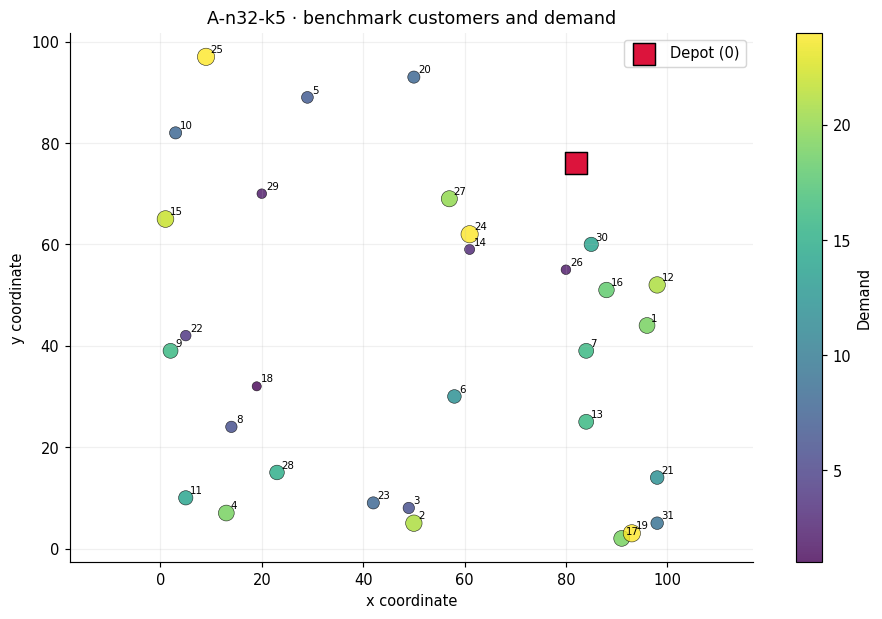

In [19]:
plot_customer_map(benchmark, "A-n32-k5 · benchmark customers and demand", label=True)

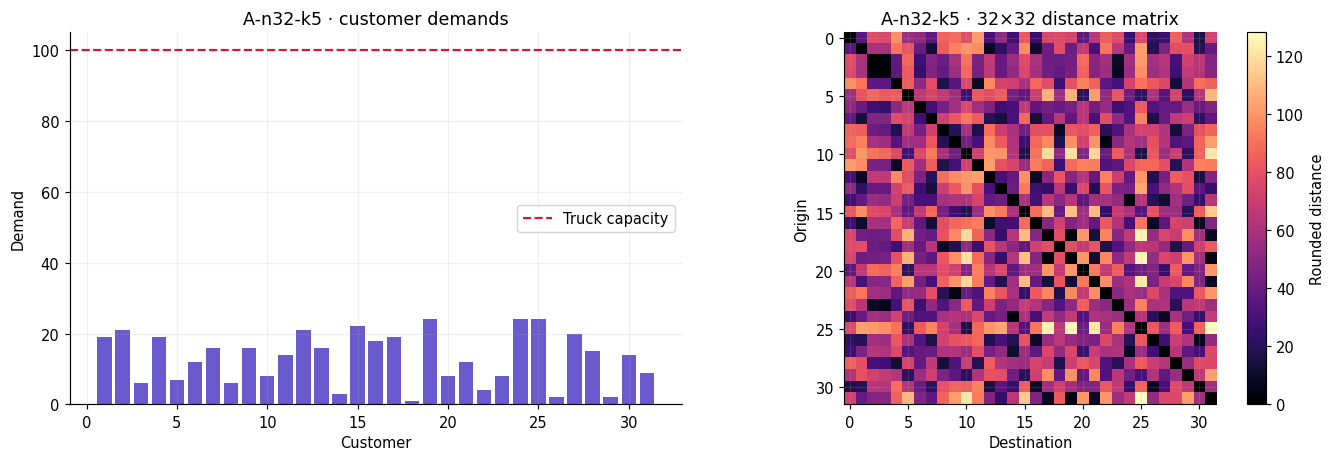

In [20]:
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(13,4.5))
q = benchmark.demands[1:]
ax1.bar(np.arange(1,len(q)+1),q,color="slateblue")
ax1.axhline(benchmark.capacity,color="crimson",linestyle="--",label="Truck capacity")
ax1.set(xlabel="Customer",ylabel="Demand",title="A-n32-k5 · customer demands")
ax1.legend()
im=ax2.imshow(benchmark.distances,cmap="magma")
fig.colorbar(im,ax=ax2,label="Rounded distance")
ax2.set(xlabel="Destination",ylabel="Origin",title="A-n32-k5 · 32×32 distance matrix")
plt.tight_layout();plt.show()

### 7.3 · Read the **published reference solution**, without optimization

The reference file lists five known routes and cost 784. It serves two purposes in this modeling deliverable: (1) validate the input conventions, and (2) check whether the mathematical rules accept a documented feasible solution. The reference cost is not a result produced by our code.

**Critical distinction:** a BKS/optimal value is an **external benchmark**, not an algorithm output. A gap calculation belongs in the later experimental deliverable, after we have actually implemented an algorithm.

In [21]:
def parse_reference_solution(path: Path) -> tuple[list[list[int]],float|None]:
    """Read a VRPLIB-style .sol; no route generation, no optimization."""
    if VRPLIB_AVAILABLE:
        record = vrplib.read_solution(str(path))
        return [list(map(int,r)) for r in record["routes"]], float(record.get("cost",np.nan))
    # Offline fallback for the small embedded .sol (same 0-based customer IDs).
    routes, cost = [], None
    for text_line in path.read_text(encoding="utf-8").splitlines():
        line=text_line.strip()
        if line.lower().startswith("route"):
            routes.append([int(x) for x in line.split(":",1)[1].split()])
        elif line.lower().startswith("cost"):
            cost=float(line.split(":",1)[-1])
    return routes,cost

reference_routes, published_cost = parse_reference_solution(SAMPLE_SOL)
reference_validation = validate_routes(benchmark, reference_routes)
reference_certificate = certify_model_equations(benchmark, reference_routes)
print("Reference routes:",len(reference_routes))
print("Published cost:",published_cost)
print("Recalculated rounded-distance cost:",reference_validation.total_distance)
print("Feasible route list:",reference_validation.feasible)
print("All MILP equations verified:",reference_certificate["all_hold"])
assert reference_validation.feasible, reference_validation.problems
assert reference_certificate["all_hold"]
assert np.isclose(reference_validation.total_distance,published_cost)
assert np.isclose(published_cost,784.0)  # Published A-n32-k5 example only.

Reference routes: 5
Published cost: 784.0
Recalculated rounded-distance cost: 784.0
Feasible route list: True
All MILP equations verified: True


### 7.4 · The benchmark's published routes, visualized

Colored lines display the already-known reference routes. The depot is marked with a square. They are provided to test the **mathematical model**, not to suggest the notebook implements route search.

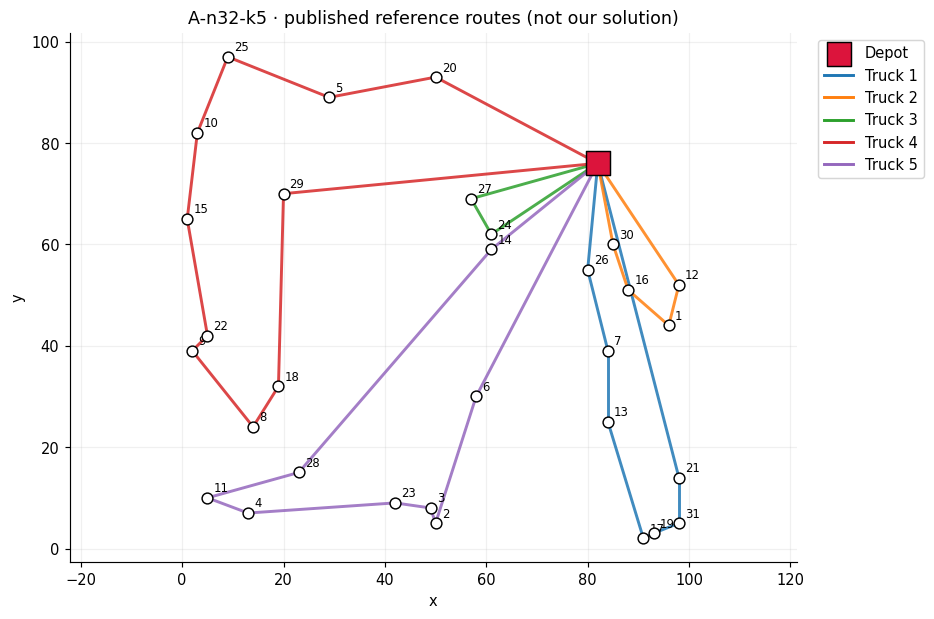

In [22]:
plot_routes(benchmark,reference_routes,"A-n32-k5 · published reference routes (not our solution)")

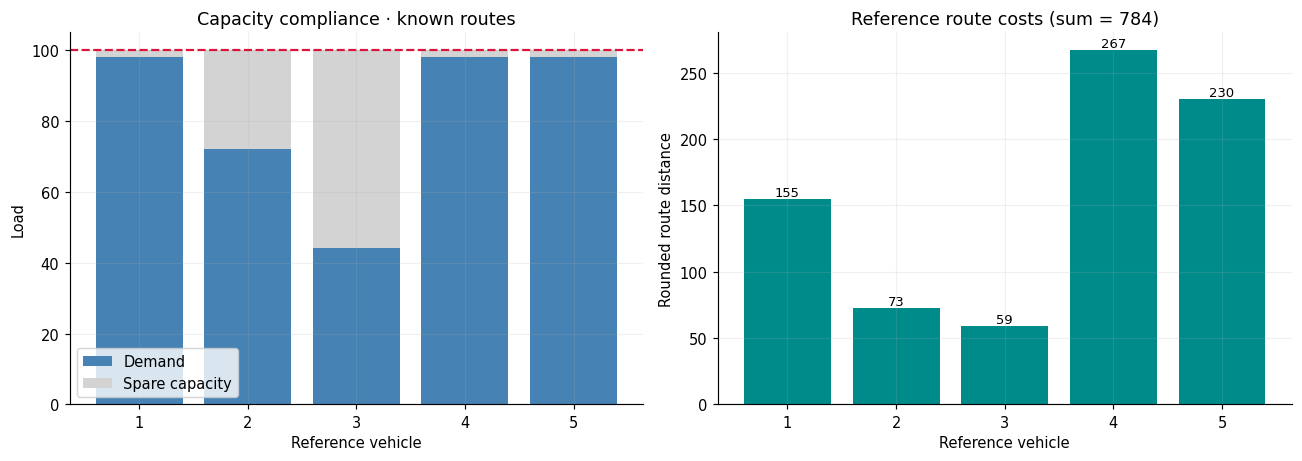

In [23]:
loads = np.array(reference_validation.route_loads)
costs = np.array(reference_validation.route_distances)
x=np.arange(1,len(loads)+1)
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12.5,4.5))
ax1.bar(x,loads,label="Demand",color="steelblue")
ax1.bar(x,benchmark.capacity-loads,bottom=loads,label="Spare capacity",color="lightgray")
ax1.axhline(benchmark.capacity,linestyle="--",color="crimson")
ax1.set(xlabel="Reference vehicle",ylabel="Load",title="Capacity compliance · known routes")
ax1.legend()
ax2.bar(x,costs,color="darkcyan")
ax2.set(xlabel="Reference vehicle",ylabel="Rounded route distance",
        title=f"Reference route costs (sum = {costs.sum():g})")
for xi, val in zip(x,costs):
    ax2.text(xi,val+2,f"{val:g}",ha="center",fontsize=9)
plt.tight_layout();plt.show()

### 7.5 · What goes wrong if distance rounding is ignored?

The histogram shows the **difference for each pairwise edge** between raw Euclidean and nearest-integer Euclidean costs. Small differences across many edges can accumulate and cause a false performance gap when compared to published rounded reference values.

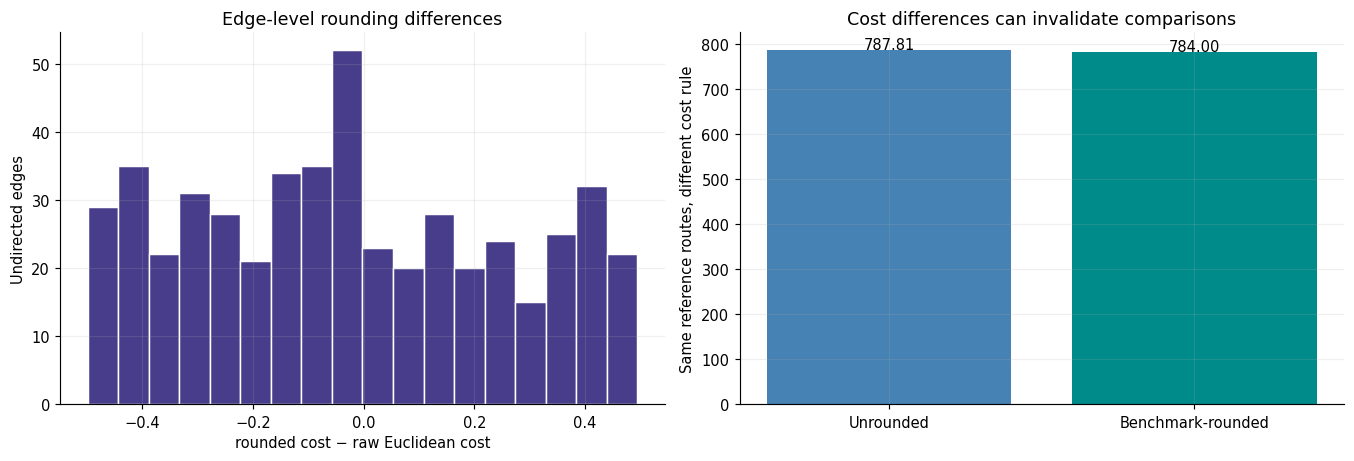

Unrounded reference cost = 787.8083
Set A nearest-integer cost = 784 (published: 784)


In [24]:
raw_D = euclidean_cost_matrix(benchmark.coordinates, "raw")
rounded_D = euclidean_cost_matrix(benchmark.coordinates, "nearest_integer")
iu = np.triu_indices_from(raw_D,k=1)
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(13,4.5))
ax1.hist((rounded_D-raw_D)[iu],bins=18,color="darkslateblue",edgecolor="white")
ax1.set(xlabel="rounded cost − raw Euclidean cost",ylabel="Undirected edges",
        title="Edge-level rounding differences")
raw_total = sum(raw_D[a,b] for route in reference_routes
                for a,b in zip([0]+route,route+[0]))
rounded_total = sum(rounded_D[a,b] for route in reference_routes
                    for a,b in zip([0]+route,route+[0]))
ax2.bar(["Unrounded", "Benchmark-rounded"],[raw_total,rounded_total],
        color=["steelblue","darkcyan"])
ax2.set(ylabel="Same reference routes, different cost rule",
        title="Cost differences can invalidate comparisons")
for a,val in zip(ax2.patches,[raw_total,rounded_total]):
    ax2.text(a.get_x()+a.get_width()/2,a.get_height()+2,f"{val:.2f}",ha="center")
plt.tight_layout();plt.show()
print(f"Unrounded reference cost = {raw_total:.4f}")
print(f"Set A nearest-integer cost = {rounded_total:.0f} (published: {published_cost:.0f})")

## 8 · Analyze parameter sensitivity **without** solving the CVRP

An important goal of mathematical modeling is recognizing how inputs affect **necessary conditions** and **model size**. The next studies vary $K$, $Q$, $n$, and spatial distribution; they never run an optimization algorithm.

### 8.1 · Capacity $Q$ vs minimum trucks from aggregate demand

For an instance with total demand $D$, the lower bound $\lceil D/Q\rceil$ decreases as capacity increases. This chart gives only a **necessary lower bound**, not an exact fleet requirement.

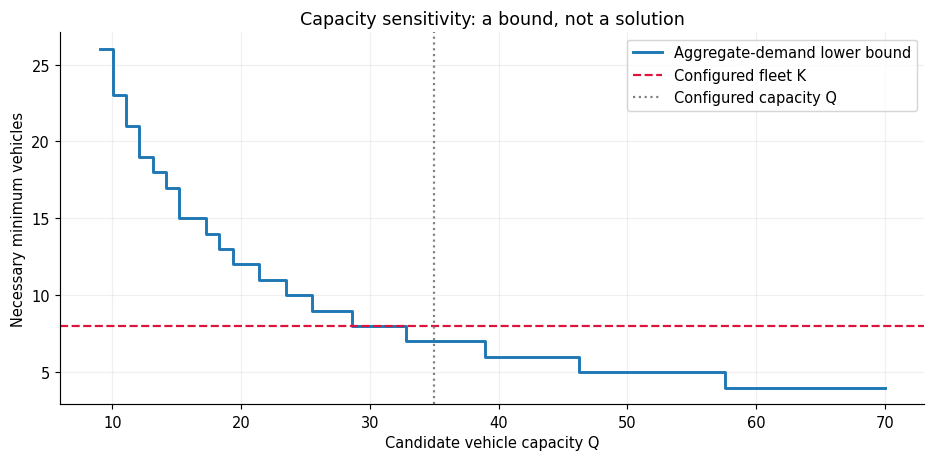

In [25]:
D_total = float(synthetic.demands[1:].sum())
max_q = float(synthetic.demands[1:].max())
# Study capacities from at least the largest individual demand up to an editable
# multiple of the configured capacity. These are experiments, not model constants.
cap_grid=np.linspace(max(1,max_q),max(max_q+1,2*SYNTHETIC.vehicle_capacity),60)
truck_lb=np.ceil(D_total/cap_grid)
fig,ax=plt.subplots(figsize=(9,4.5))
ax.step(cap_grid,truck_lb,where="post",lw=2,label="Aggregate-demand lower bound")
ax.axhline(SYNTHETIC.max_vehicles,color="crimson",linestyle="--",label="Configured fleet K")
ax.axvline(SYNTHETIC.vehicle_capacity,color="gray",linestyle=":",label="Configured capacity Q")
ax.set(xlabel="Candidate vehicle capacity Q",ylabel="Necessary minimum vehicles",
       title="Capacity sensitivity: a bound, not a solution")
ax.legend()
plt.tight_layout();plt.show()

### 8.2 · How does the full ILP formulation scale?

For a complete directed graph with $n$ customers and $K$ trucks, our formulation creates:

- $K(n+1)n$ binary arc variables $x$ (no diagonal),
- $Kn$ binary assignment variables $y$,
- $K$ binary vehicle-use variables $z$,
- $Kn$ continuous order variables $u$.

Therefore the number of binary variables is $K(n^2+2n+1)=K(n+1)^2$, and continuous variables number $Kn$. The number of order inequalities alone is $Kn(n-1)$ — quadratic in customers and linear in vehicles. This is why we **model with ILP now**, but should later use an efficient heuristic for large instances.

These are **representation sizes**, not execution time predictions and not experimental algorithm results.

In [26]:
def model_sizes(n: int, k: int) -> dict[str,int]:
    """Count decision variables and major constraint families algebraically."""
    if n<1 or k<1:
        raise ValueError("n and K must be positive")
    return {
        "arcs (binary)":k*(n+1)*n,
        "assignments (binary)":k*n,
        "vehicle-use (binary)":k,
        "order (continuous)":k*n,
        "MTZ pairwise inequalities":k*n*(n-1),
        "degree equalities":2*k*n,
        "customer assignment eqs":n,
        "depot equalities":2*k,
        "capacity inequalities":k,
        "order-bound inequalities":2*k*n,
    }

sizes=model_sizes(benchmark.n_customers,benchmark.max_vehicles)
display(pd.DataFrame(sizes.items(),columns=["Component","Count"]))
assert sizes["arcs (binary)"] == benchmark.max_vehicles*(benchmark.n_customers+1)*benchmark.n_customers
assert sum(sizes[k] for k in ["arcs (binary)","assignments (binary)","vehicle-use (binary)"]) == benchmark.max_vehicles*(benchmark.n_customers+1)**2

,Component,Count
0,arcs (binary),4960
1,assignments (binary),155
2,vehicle-use (binary),5
3,order (continuous),155
4,MTZ pairwise inequalities,4650
5,degree equalities,310
6,customer assignment eqs,31
7,depot equalities,10
8,capacity inequalities,5
9,order-bound inequalities,310


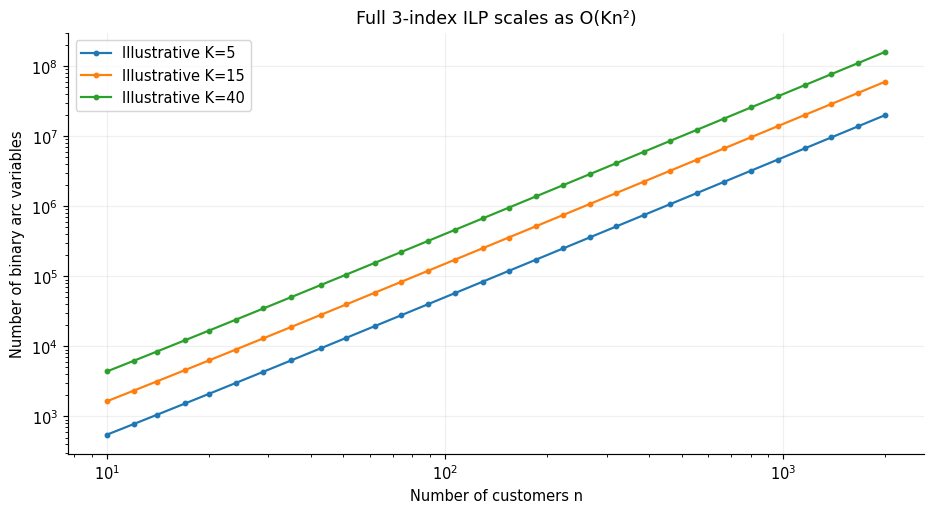

In [27]:
# Compare symbolic model sizes for three possible fleet-scaling scenarios.
n_grid=np.unique(np.geomspace(10,2000,num=30).astype(int))
fig,ax=plt.subplots(figsize=(9,5))
for assumed_K in (5,15,40):  # Scenario values only; not hard-coded fleet limits.
    arc_vars=[model_sizes(int(n),assumed_K)["arcs (binary)"] for n in n_grid]
    ax.plot(n_grid,arc_vars,marker=".",label=f"Illustrative K={assumed_K}")
ax.set(xlabel="Number of customers n",ylabel="Number of binary arc variables",
       title="Full 3-index ILP scales as O(Kn²)",xscale="log",yscale="log")
ax.legend()
plt.tight_layout();plt.show()

### 8.3 · Spatial distribution: uniform vs clustered customers

Customer geometry is part of the **input**, not a mathematical constraint: uniform and clustered instances can have the same number of customers, identical capacities and similar demand distributions, yet very different routing structure.

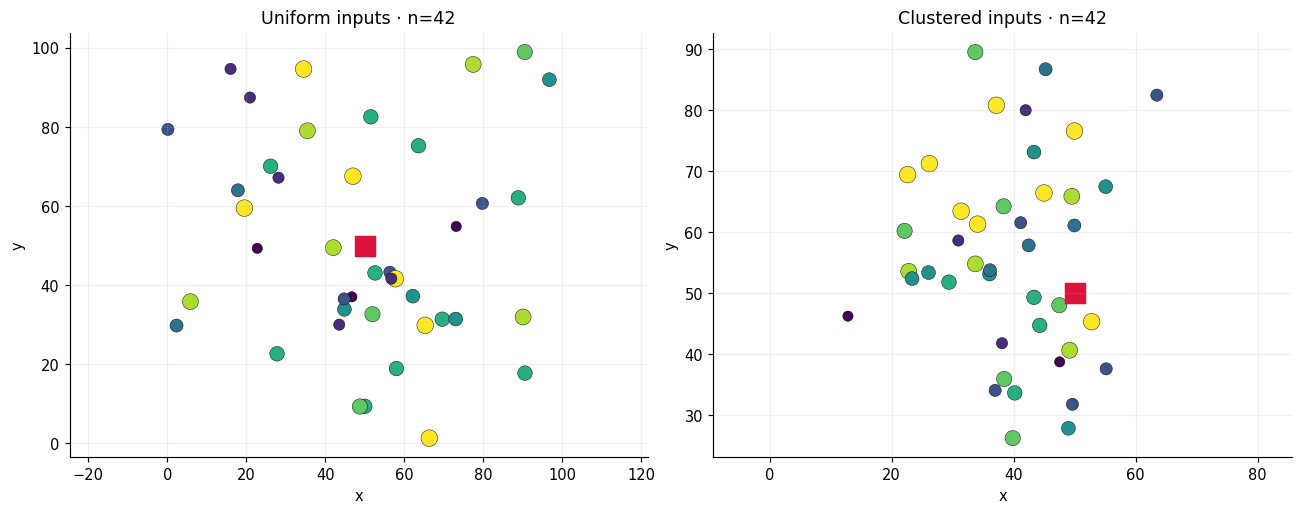

In [28]:
# Use the same configurable values and random seed, changing only layout.
from dataclasses import replace
uniform_demo = generate_synthetic(replace(SYNTHETIC, layout="uniform"))
clustered_demo = generate_synthetic(replace(SYNTHETIC, layout="clustered"))
fig,axs=plt.subplots(1,2,figsize=(12.5,5))
for ax,inst,label in zip(axs,[uniform_demo,clustered_demo],["Uniform", "Clustered"]):
    xy=inst.coordinates
    ax.scatter(xy[1:,0],xy[1:,1],s=40+10*inst.demands[1:],
               c=inst.demands[1:],cmap="viridis",edgecolor="black",lw=.3)
    ax.scatter([xy[0,0]],[xy[0,1]],s=200,marker="s",color="crimson")
    ax.set(xlabel="x",ylabel="y",title=f"{label} inputs · n={inst.n_customers}")
    ax.set_aspect("equal",adjustable="datalim")
plt.tight_layout();plt.show()

### 8.4 · Fleet-and-capacity necessary feasibility map

The heatmap below marks whether $KQ\ge\sum_i q_i$ — an **aggregate necessity test only**. A green cell means *not ruled out* by total capacity; it does **not** prove route feasibility. A red cell is definitely infeasible by this bound.

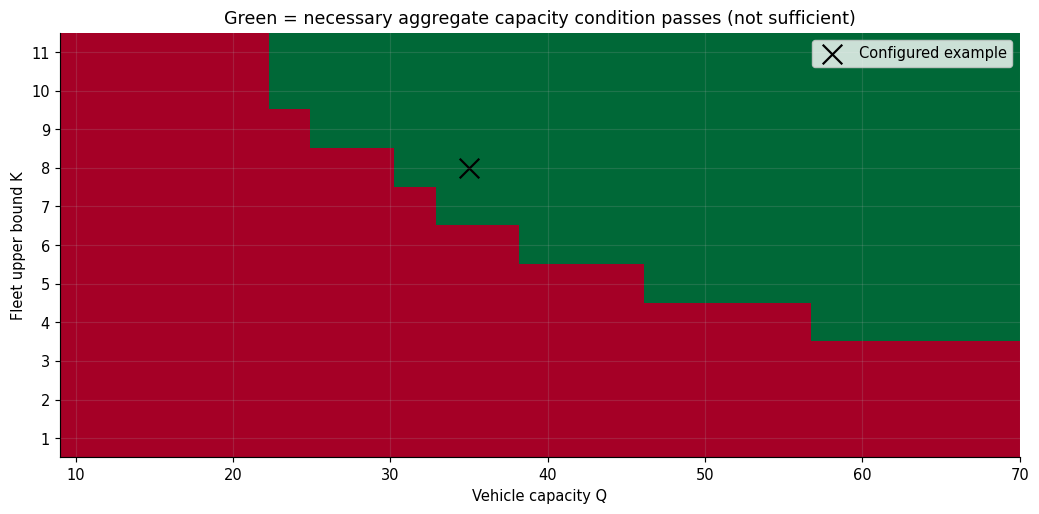

In [29]:
qsum=float(synthetic.demands[1:].sum())
max_q=float(synthetic.demands[1:].max())
K_values=np.arange(1,max(9,SYNTHETIC.max_vehicles+4))
Q_values=np.linspace(max(1,max_q),max(2*SYNTHETIC.vehicle_capacity,max_q+1),23)
feasible_capacity=np.array([[k*q>=qsum and q>=max_q for q in Q_values] for k in K_values])
fig,ax=plt.subplots(figsize=(10,5))
img=ax.imshow(feasible_capacity,aspect="auto",origin="lower",cmap="RdYlGn",
              interpolation="nearest",extent=[Q_values[0],Q_values[-1],K_values[0]-.5,K_values[-1]+.5])
ax.scatter([synthetic.capacity],[synthetic.max_vehicles],marker="x",s=180,
           color="black",label="Configured example")
ax.set(xlabel="Vehicle capacity Q",ylabel="Fleet upper bound K",
       title="Green = necessary aggregate capacity condition passes (not sufficient)")
ax.set_yticks(K_values)
ax.legend()
plt.tight_layout();plt.show()

## 9 · Review of edge cases and modeling boundaries

| Situation | Expected model behavior |
|---|---|
| $K=1$, $Q\ge\sum_i q_i$ | TSP special case; one connected route visits all customers |
| $q_i=Q$ | The customer's truck cannot serve any other customer with positive demand |
| $q_i=0$ | Customer must still be visited; order-based MTZ remains valid |
| Some trucks unused | Corresponding $z_k=0$, and no arcs/customers can be assigned to them |
| Total demand exceeds $KQ$ | Provably infeasible before optimization |
| $KQ\ge\sum_i q_i$ | Only a necessary condition; still may be infeasible due to unsplittable demands |
| Asymmetric $d_{ij}$ | Directed formulation still valid |
| Non-metric distances | Directed formulation still valid; geometric plotting is only illustrative |
| No coordinates | Mathematics remains valid if the distance matrix is supplied; map plots are skipped |
| No specified fleet bound | **Ask for a bound / use documented benchmark metadata** rather than fix one in the solver |
| $n\gg 1000$ | Full $K(n+1)n$ arc variable set is very large; modeling remains correct but exact solving is costly |

**Scope-specific note:** no timing variables or arrival/departure-dependent costs appear anywhere in this model. Introducing them would change the selected basic-CVRP problem into a more advanced variant.

## 10 · Optional user-provided `.vrp` instance: how to reuse this notebook

1. Place a CVRP `.vrp` file in your working directory, e.g. `my_instance.vrp`.
2. Install `vrplib` to support general formats.
3. Call `load_cvrp("my_instance.vrp", fleet_override=..., rounding="...")`.
4. Choose the correct distance convention **for that benchmark family**, not necessarily `nearest_integer`.
5. Check `instance.check_input()` and use the input plots; if a known route file exists, read and validate it.
6. Do **not** infer the achieved quality of an algorithm until there is an algorithm whose result is being evaluated.

The standalone example below is not executed unless you supply a file. It is a safe template for the **future** dataset-collection step.

```python
# new_instance = load_cvrp(
#     "my_instance.vrp",
#     fleet_override=None,     # Or a fleet integer if the file doesn't specify it.
#     rounding="raw",         # CHANGE to the benchmark's documented rule.
# )
# print(new_instance.check_input())
# plot_customer_map(new_instance)
```

## 11 · What to take to the tutor checkpoint

**Model to defend:** the sets $V,C,F,A$; input data $d_{ij},q_i,Q,K$; binary decisions $x,y,z$; MTZ auxiliary $u$; minimization of total distance; coverage/flow/depot/capacity/subtour constraints; and NP-hardness via TSP.

**Questions for tutor validation:**
1. Is the fleet interpretation **at most $K$** or **exactly $K$ used**?
2. Does the project evaluate **distance** (for VRPLIB) as the model objective, with traffic effects reserved as a later extension?
3. Should the benchmark use the original source fleet count when metadata are missing, or should the project explicitly configure it?
4. Are there any additional rules about demands, depot identity, symmetry, or maximum allowed routes in the provided instances?

**What remains after this check:** incorporate tutor corrections; implement a separate, parameterized route-construction heuristic and a metaheuristic; benchmark on at least 20 instances with repeated runs; report gaps, speed, robustness, limits; prepare the final notebook and an English oral presentation.

### Corrections / review log (fill in after tutor meeting)

| Date | Tutor feedback | Mathematical change | Verified by |
|---|---|---|---|
| TBD | Pending review | Pending | Team |

**No claim of tutor approval or optimal route computation is made in this notebook.**

## 12 · Scientific and technical references

1. Dantzig, G. B., & Ramser, J. H. (1959). **The Truck Dispatching Problem**. *Management Science*, 6(1), 80–91. https://doi.org/10.1287/mnsc.6.1.80
2. Clarke, G., & Wright, J. W. (1964). **Scheduling of Vehicles from a Central Depot to a Number of Delivery Points**. *Operations Research*, 12(4), 568–581. https://doi.org/10.1287/opre.12.4.568
3. Miller, C. E., Tucker, A. W., & Zemlin, R. A. (1960). **Integer Programming Formulation of Traveling Salesman Problems**. *Journal of the ACM*, 7(4), 326–329. https://doi.org/10.1145/321043.321046
4. Toth, P., & Vigo, D. (eds.). (2014). **Vehicle Routing: Problems, Methods, and Applications** (2nd ed.). SIAM. https://doi.org/10.1137/1.9781611973594
5. Uchoa, E., Pecin, D., Pessoa, A., Poggi, M., Vidal, T., & Subramanian, A. (2017). **New Benchmark Instances for the Capacitated Vehicle Routing Problem**. *European Journal of Operational Research*, 257(3), 845–858. https://doi.org/10.1016/j.ejor.2016.08.012
6. Augerat, P., Belenguer, J. M., Benavent, E., Corberán, A., Naddef, D., & Rinaldi, G. (1995). **Computational Results with a Branch and Cut Code for the Capacitated Vehicle Routing Problem**. Research report, Université Joseph Fourier, Grenoble.
7. **CVRPLIB benchmark catalog** — benchmark datasets and known reference costs: https://galgos.inf.puc-rio.br/cvrplib/
8. **PyVRP/VRPLIB Python reader** — parsing details, distance conventions and `.sol` format: https://github.com/PyVRP/VRPLIB
9. **A-n32-k5 dataset mirror** — original numeric example embedded in this notebook: https://github.com/mkalinowski/CVRP/blob/master/dane/A-n32-k5.vrp
10. **Published illustration of A-n32-k5 routes** — reference route sequences for the modeling checks: https://ltu.diva-portal.org/smash/get/diva2%3A1972726/FULLTEXT01.pdf

**Interpretation note:** the presence of a benchmark optimum (784) proves nothing about the quality of this notebook's algorithm, because **no optimization algorithm is implemented here**. It is used only for reference-route validation.

---
### End-of-notebook verification

If the notebook ran successfully, we have established that:
- Synthetic input generation and plots are repeatable for a chosen seed.
- The mathematical model is parameterized in $n,K,Q,q_i,d_{ij}$.
- Hand-written valid routes satisfy every listed model equation.
- Deliberately invalid routes are detected.
- An actual A-n32-k5 reference solution satisfies the proposed constraints.
- The published rounded benchmark cost can be reproduced exactly.

**Next phase only after mathematical review:** design and implement the actual CVRP heuristic/metaheuristic, then perform experimental benchmarking.